# 🖼️ Image Generation

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nawooooojin/openai-api-tutorial-kr/blob/main/2_Multimodal_Generation/01-Image%20Generation-Lecture.ipynb)

> **주의:** Colab 런타임을 재시작하면 `OPENAI_API_KEY` 환경 변수를 다시 설정해야 합니다.

## 1) 환경 준비 및 API 키 설정

In [ ]:
%pip install -q -U openai pillow

In [1]:
# Colab에서 실행 중이라면 실습 데이터(data/)가 있는 레포를 받아옵니다.
# (로컬에서 레포를 clone 해서 실행 중이라면 그냥 넘어갑니다)
import os, sys

if "google.colab" in sys.modules and not os.path.exists("data"):
    !git clone -q --depth 1 https://github.com/nawooooojin/openai-api-tutorial-kr.git /content/openai-api-tutorial-kr
    %cd /content/openai-api-tutorial-kr/2_Multimodal_Generation

### API 키 설정 및 Client 생성
- **Colab**: 왼쪽 메뉴 `보안 비밀(열쇠 아이콘)`에 `OPENAI_API_KEY`를 저장하고 **노트북 액세스**를 켜 두면 자동으로 불러옵니다.
- **로컬**: 환경 변수 `OPENAI_API_KEY`를 미리 설정해 두거나, 아래 셀을 실행했을 때 뜨는 입력창에 키를 붙여넣으면 됩니다.
- 아래의 코드에서 오류가 난다면 API 키의 오류일 가능성이 높습니다.

In [2]:
import os

OPENAI_API_KEY = os.environ.get("OPENAI_API_KEY")
if not OPENAI_API_KEY:
    try:
        from google.colab import userdata  # type: ignore
        OPENAI_API_KEY = userdata.get("OPENAI_API_KEY")
    except ImportError:
        pass  # Colab이 아닌 환경
    except Exception:
        print("Colab 메뉴의 보안 비밀(열쇠 아이콘)에 OPENAI_API_KEY가 저장되어 있는지, 노트북 액세스가 켜져 있는지 확인해주세요.")

if not OPENAI_API_KEY:
    from getpass import getpass
    OPENAI_API_KEY = getpass("OPENAI_API_KEY를 입력하세요: ")

os.environ["OPENAI_API_KEY"] = OPENAI_API_KEY
print("✅ API 키 설정 완료")

✅ API 키 설정 완료


In [3]:
base_dirs = [
    ("data", ["image", "audio", "video"]),
    ("results", ["image", "audio", "video"]),
]

for root, subfolders in base_dirs:
    for sub in subfolders:
        path = os.path.join(root, sub)
        os.makedirs(path, exist_ok=True)
        print(f"ready: {path}")

ready: data/image
ready: data/audio
ready: data/video
ready: results/image
ready: results/audio
ready: results/video


In [4]:
from openai import OpenAI

client = OpenAI()
print("✅ 클라이언트 생성 완료")

✅ 클라이언트 생성 완료


In [5]:
import io
from IPython.display import Image as IPyImage, display
from PIL import Image


def show_image(path, max_size=512):
    """저장된 이미지를 노트북에서 작게 미리보기합니다. (투명 배경은 회색으로 표시)"""
    img = Image.open(path)
    img.thumbnail((max_size, max_size))
    if img.mode in ("RGBA", "LA", "P"):
        img = img.convert("RGBA")
        background = Image.new("RGBA", img.size, (220, 220, 220, 255))
        img = Image.alpha_composite(background, img)
    buffer = io.BytesIO()
    img.convert("RGB").save(buffer, format="JPEG", quality=85)
    display(IPyImage(data=buffer.getvalue()))

## 2) GPT Image 개요 및 API 비교

### Image Generation 개요

OpenAI API를 사용하면 텍스트 프롬프트로 이미지를 생성하거나, 기존 이미지를 편집할 수 있습니다.

**OpenAI에서 제공하는 이미지 생성 API**
- **Image API**: 이미지 생성/편집 전용 API
- **Responses API**: 대화형 모델(GPT)에서 이미지 툴을 활용

### Image API

**제공 기능**
- **`Generations`**: 텍스트 프롬프트만으로 이미지를 새로 생성
- **`Edits`**: 기존 이미지를 프롬프트에 따라 전체/부분 편집

**지원 모델**
- `gpt-image-2.5-sunburst`, `gpt-image-2.5-flare`, `gpt-image-2`

### Responses API

**특징**
- 대화 흐름 속에서 이미지 생성/편집을 섞어 사용 가능
- 이미지 생성은 내장 도구(`image_generation` tool) 형태로 제공
- **멀티턴 편집**: 한 번 만든 이미지를 계속 수정하여 고품질 편집 가능
- **입력 유연성**: 바이트뿐 아니라 File API로 업로드한 `file_id`를 이미지 입력으로 사용 가능

**모델 지정 방식**
- `model` 파라미터에는 대화를 이끄는 GPT 모델(예: `gpt-6-luna`)을 넣고,
- 실제로 그림을 그리는 이미지 모델은 tool 안의 `"model"`로 지정합니다. (예: `{"type": "image_generation", "model": "gpt-image-2.5-flare"}`)

### 모델 비교

| 모델 | 특징 | 비고 |
| --- | --- | --- |
| **gpt-image-2.5-sunburst** | 가장 성능이 좋은 이미지 생성·편집 모델. 편집 정밀도가 중요한 작업에 적합 | 2026.09 출시 |
| **gpt-image-2.5-flare** | 빠르고 가벼운 일상용 이미지 생성 모델 | 2026.09 출시 |
| **gpt-image-2** | 이전 세대 모델 | 2026.04 출시 |

- GPT Image 모델은 조직 인증(Organization Verification)이 필요할 수 있습니다.
- 이미지 생성은 텍스트보다 비용이 꽤 나가는 편이라, 실습에서는 `quality`를 `low` / `medium`으로 두는 것을 추천합니다.

## 3) Responses API로 이미지 생성 실습
Responses API에서 이미지 생성 도구를 호출하면 텍스트 생성과 동일한 흐름 안에서 결과를 받을 수 있습니다.

✅ 이미지 저장 완료 -> results/image/cat_and_otter.png


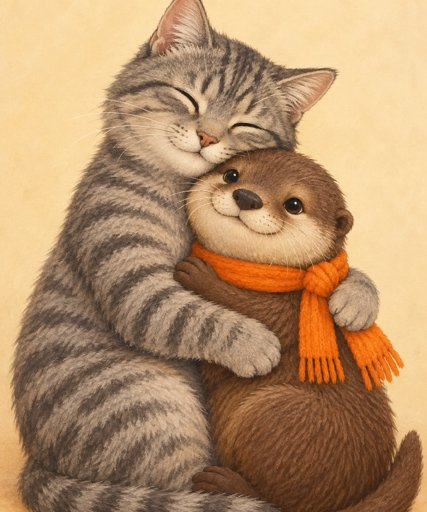

In [6]:
import base64

prompt = "회색 줄무늬 고양이가 오렌지색 스카프를 한 수달을 껴안고 있는 이미지를 생성해주세요"

response = client.responses.create(
    model="gpt-6-luna",
    input=prompt,
    tools=[{"type": "image_generation", "model": "gpt-image-2.5-flare", "quality": "medium"}],
)

image_data = [
    output.result
    for output in response.output
    if output.type == "image_generation_call"
]

if image_data:
    image_bytes = base64.b64decode(image_data[0])
    with open("results/image/cat_and_otter.png", "wb") as f:
        f.write(image_bytes)
    print("✅ 이미지 저장 완료 -> results/image/cat_and_otter.png")
    show_image("results/image/cat_and_otter.png")
else:
    print("이미지 생성 결과가 존재하지 않습니다.")

## 4) 이미지 출력 옵션(사이즈 · 품질 · 배경)
- **`size`**: 이미지 크기 (`1024x1024`, `1024x1536`, `1536x1024`, `auto` 등)
- **`quality`**: 품질 (`low`, `medium`, `high`, `xhigh`, `max`, `auto`)
- **`output_format`**: 포맷 (`png`, `jpeg`, `webp`)
- **`output_compression`**: 압축률
- **`background`**: 배경 투명 여부 (`transparent` 설정 가능)

✅ 투명 배경 스프라이트 저장 완료 -> results/image/sprite.png


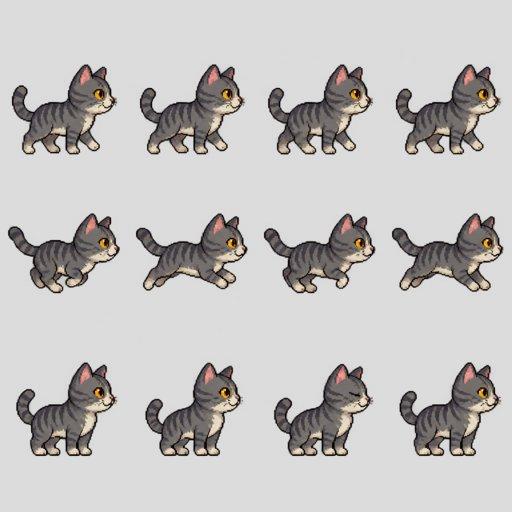

In [7]:
import base64

styled_prompt = "회색 줄무늬 고양이의 2D 픽셀 아트 스타일 스프라이트 시트를 그려주세요"

response = client.responses.create(
    model="gpt-6-luna",
    input=styled_prompt,
    tools=[
        {
            "type": "image_generation",
            "model": "gpt-image-2.5-flare",
            "size": "1024x1024",
            "quality": "low",
            "background": "transparent",
        }
    ],
)

image_data = [
    output.result
    for output in response.output
    if output.type == "image_generation_call"
]

if image_data:
    sprite_bytes = base64.b64decode(image_data[0])
    with open("results/image/sprite.png", "wb") as f:
        f.write(sprite_bytes)
    print("✅ 투명 배경 스프라이트 저장 완료 -> results/image/sprite.png")
    show_image("results/image/sprite.png")

## 5) 멀티턴 이미지 개선과 스트리밍

**멀티턴 이미지 개선**
- 이미지 생성 후 `previous_response_id`를 사용하여 같은 대화 맥락에서 후속 지시를 내려 변형할 수 있습니다.
- 한 번 만든 이미지를 계속 수정하여 고품질 편집이 가능합니다.

**스트리밍**
- `stream=True` 옵션을 사용하면 생성 중간 결과도 실시간으로 확인할 수 있습니다.
- 부분 이미지를 스트리밍으로 받아 더 인터랙티브한 경험을 제공합니다.

✅ 우주복 호랑이 & 로봇 저장 완료 -> results/image/tiger_and_robot.png


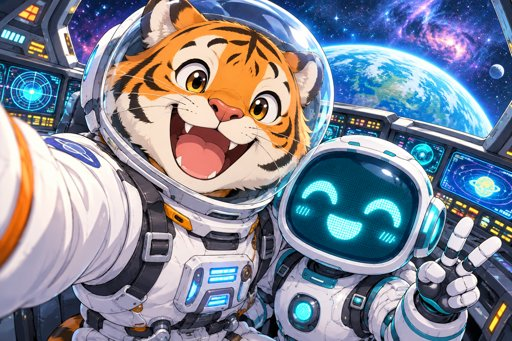

In [8]:
base_prompt = "우주복을 입은 호랑이와 웃는 LED 얼굴 로봇이 우주선 조종석에서 셀카 찍는 장면을 만화풍으로 그려주세요."
response = client.responses.create(
    model="gpt-6.1-sol",
    input=base_prompt,
    tools=[{"type": "image_generation", "model": "gpt-image-2.5-flare", "quality": "medium"}],
)

image_data = [
    output.result
    for output in response.output
    if output.type == "image_generation_call"
]

if image_data:
    tiger_bytes = base64.b64decode(image_data[0])
    with open("results/image/tiger_and_robot.png", "wb") as f:
        f.write(tiger_bytes)
    print("✅ 우주복 호랑이 & 로봇 저장 완료 -> results/image/tiger_and_robot.png")
    show_image("results/image/tiger_and_robot.png")

✅ 후속 이미지 저장 -> results/image/tiger_and_robot_realistic.png


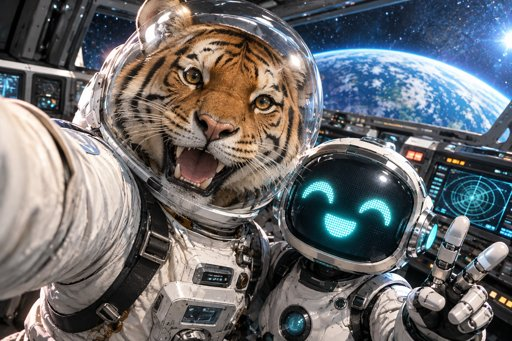

In [9]:
# 후속 지시
response_followup = client.responses.create(
    model="gpt-6.1-sol",
    previous_response_id=response.id,
    input="사실적인 이미지로 만들어줘.",
    tools=[{"type": "image_generation", "model": "gpt-image-2.5-flare", "quality": "medium"}],
)

followup_data = [
    output.result
    for output in response_followup.output
    if output.type == "image_generation_call"
]

if followup_data:
    refined_bytes = base64.b64decode(followup_data[0])
    with open("results/image/tiger_and_robot_realistic.png", "wb") as f:
        f.write(refined_bytes)
    print("✅ 후속 이미지 저장 -> results/image/tiger_and_robot_realistic.png")
    show_image("results/image/tiger_and_robot_realistic.png")

### 프롬프트 자동 개선 (Revised Prompt)

Responses API에서 이미지 생성 도구를 사용할 때, 메인 모델(예: `gpt-6.1-sol`)이 성능 향상을 위해 프롬프트를 자동으로 개선합니다.

**개선된 프롬프트 확인**
- 이미지 생성 호출 결과의 `revised_prompt` 필드에서 개선된 프롬프트를 확인할 수 있습니다.
- 원본 프롬프트와 비교하여 모델이 어떻게 해석했는지 파악할 수 있습니다.

In [10]:
for output in response.output:
    if output.type == "image_generation_call":
        print("📝 원본 프롬프트 :", base_prompt)
        print("✨ 개선된 프롬프트:", output.revised_prompt)

📝 원본 프롬프트 : 우주복을 입은 호랑이와 웃는 LED 얼굴 로봇이 우주선 조종석에서 셀카 찍는 장면을 만화풍으로 그려주세요.
✨ 개선된 프롬프트: 만화풍 디지털 일러스트. 우주선 조종석 안에서 우주복을 입은 호랑이와 웃는 LED 얼굴 로봇이 다정하게 함께 셀카를 찍는 장면. 호랑이는 주황색 털과 검은 줄무늬, 투명한 둥근 헬멧과 디테일한 흰 우주복을 입고 활짝 웃으며 한쪽 앞발로 카메라를 화면 앞쪽으로 뻗고 있다. 옆의 귀여운 로봇은 청록빛 LED 화면에 웃는 눈과 입이 선명하고 한 손으로 브이 포즈를 하고 있다. 셀카 광각 시점, 두 캐릭터 얼굴이 크게 보이는 생동감 있는 구도. 배경에는 다채롭게 빛나는 조종석 계기판과 커다란 창 너머의 별, 푸른 행성, 성운이 보인다. 밝고 유쾌한 분위기, 선명한 윤곽선, 풍부하고 산뜻한 색채, 부드러운 셀 셰이딩, 높은 완성도의 SF 어드벤처 애니메이션 스타일. 글자나 워터마크 없이.


### Streaming

이미지가 생성되는 과정에서 부분 이미지를 스트리밍으로 받아 더 인터랙티브한 경험을 할 수 있습니다.

**주요 특징**
- **`partial_images` 파라미터**: 0-3 사이의 값을 설정하여 중간 이미지 수를 조절할 수 있습니다.
- **`partial_images=0`**: 최종 이미지만 받습니다.
- **`partial_images>0`**: 요청한 수보다 적게 받을 수 있습니다 (이미지가 빠르게 생성되는 경우).

**활용 사례**
- 실시간 이미지 생성 진행 상황 확인
- 사용자에게 생성 과정을 보여주는 인터랙티브 UI 구현

✅ 중간 이미지 0 저장 완료 -> results/image/river0.png


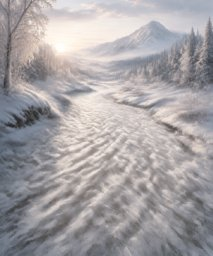

🏁 최종 이미지 저장 완료 -> results/image/river_final.png


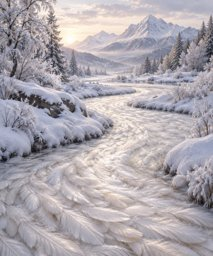

In [11]:
from openai import OpenAI
import base64

client = OpenAI()

stream = client.responses.create(
    model="gpt-6-luna",
    input="하얀 올빼미 깃털로 만들어진 아름다운 강이 고요한 겨울 풍경을 가로지르며 흐르는 이미지를 그려주세요",
    stream=True,
    tools=[{"type": "image_generation", "model": "gpt-image-2.5-flare", "quality": "medium", "partial_images": 2}],
)

for event in stream:
    # 생성 중간 결과 (partial image)
    if event.type == "response.image_generation_call.partial_image":
        idx = event.partial_image_index
        image_bytes = base64.b64decode(event.partial_image_b64)
        with open(f"results/image/river{idx}.png", "wb") as f:
            f.write(image_bytes)
        print(f"✅ 중간 이미지 {idx} 저장 완료 -> results/image/river{idx}.png")
        show_image(f"results/image/river{idx}.png", max_size=256)

    # 최종 결과
    elif event.type == "response.output_item.done" and event.item.type == "image_generation_call":
        with open("results/image/river_final.png", "wb") as f:
            f.write(base64.b64decode(event.item.result))
        print("🏁 최종 이미지 저장 완료 -> results/image/river_final.png")
        show_image("results/image/river_final.png", max_size=256)

## 6) 이미지 편집 (edit)

이미지 생성뿐 아니라 기존 이미지를 참고하거나 부분적으로 수정하는 기능을 활용할 수 있습니다.

**주요 기능**
- **참고 이미지 활용**: 기존 이미지를 입력으로 제공하여 참고하여 새로운 이미지를 생성할 수 있습니다.
- **부분 편집**: 프롬프트와 함께 기존 이미지를 입력하여 특정 부분만 수정할 수 있습니다.

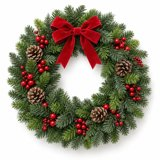

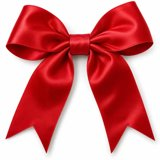

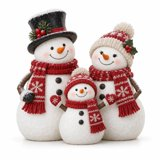

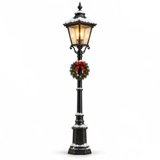

In [12]:
def encode_image(file_path):
    with open(file_path, "rb") as f:
        base64_image = base64.b64encode(f.read()).decode("utf-8")
    return base64_image

# 참고할 소품 이미지 미리보기
for name in ["2_wreath", "3_ribbon", "4_snowman", "5_lamp"]:
    show_image(f"data/image/{name}.webp", max_size=160)

🎄 크리스마스 트리 장면 생성 완료 -> results/image/christmas_tree_scene.png


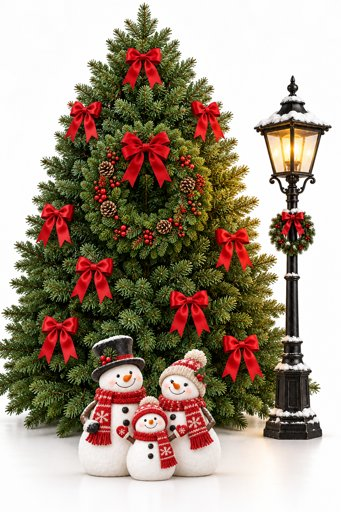

In [13]:
prompt = (
    "Create a photorealistic Christmas tree scene on a pure white background.\n\n"
    "Generate a new, undecorated Christmas tree from scratch. "
    "Then decorate this tree using ONLY the items shown in the reference images:\n"
    "- Use the wreath as a large decorative ornament placed prominently.\n"
    "- Use the red ribbon as multiple bows across the branches.\n"
    "- Place the snowman family in front of the tree as part of the scene.\n"
    "- Include the street lamp standing to the right side of the tree, lighting the scene.\n\n"
    "The final result should look like one cohesive high-quality product photo."
)

contents = [
    {"type": "input_text", "text": prompt},
    {"type": "input_image", "image_url": f"data:image/webp;base64,{encode_image('data/image/2_wreath.webp')}"},
    {"type": "input_image", "image_url": f"data:image/webp;base64,{encode_image('data/image/3_ribbon.webp')}"},
    {"type": "input_image", "image_url": f"data:image/webp;base64,{encode_image('data/image/4_snowman.webp')}"},
    {"type": "input_image", "image_url": f"data:image/webp;base64,{encode_image('data/image/5_lamp.webp')}"},
]


response = client.responses.create(
    model="gpt-6.1-sol",
    input=[{"role": "user", "content": contents}],
    tools=[{"type": "image_generation", "model": "gpt-image-2.5-sunburst", "quality": "medium"}],
)

edit_data = [
    output.result
    for output in response.output
    if output.type == "image_generation_call"
]

if edit_data:
    edited_bytes = base64.b64decode(edit_data[0])
    with open("results/image/christmas_tree_scene.png", "wb") as f:
        f.write(edited_bytes)
    print("🎄 크리스마스 트리 장면 생성 완료 -> results/image/christmas_tree_scene.png")
    show_image("results/image/christmas_tree_scene.png")

### 정밀 편집

- 로고 합성처럼 원본 디테일을 잘 보존해야 하는 작업은 편집 정밀도에 초점을 둔 `gpt-image-2.5-sunburst`를 사용합니다.
- Tip: 보존해야 하는 이미지(예: 로고)를 첫 번째 입력 이미지로 넣고, 프롬프트에서 "무엇을 바꾸지 말아야 하는지"를 구체적으로 적어주세요.

🎉 아주대 로고 프린팅 티셔츠 생성 완료 → results/image/ajou_tshirt.png


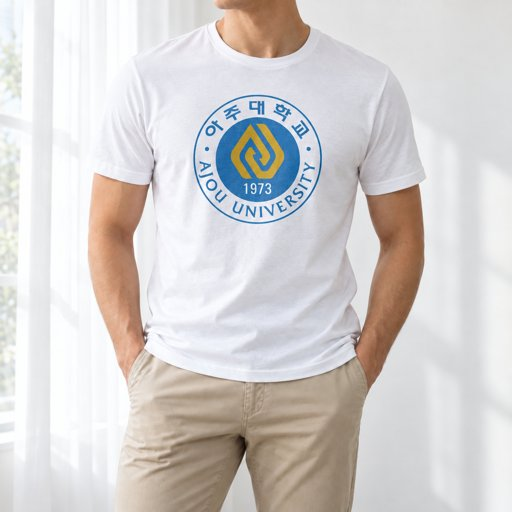

In [14]:
from openai import OpenAI
import base64

client = OpenAI()

def encode_image(file_path):
    with open(file_path, "rb") as f:
        base64_image = base64.b64encode(f.read()).decode("utf-8")
    return base64_image

# 이미지 불러오기
ajou_logo = encode_image("data/image/ajou_logo.png")
tshirt_image = encode_image("data/image/white_tshirt.jpg")

# 프롬프트
prompt = (
    "Place the Ajou University logo onto the white T-shirt in a photorealistic way. "
    "The logo should look naturally printed on the fabric, following the shirt’s folds, "
    "lighting, and texture. Do not alter the person's body or pose; only modify the shirt. "
    "Keep the original scene, pose, and lighting identical."
)

response = client.responses.create(
    model="gpt-6.1-sol",
    input=[
        {
            "role": "user",
            "content": [
                {"type": "input_text", "text": prompt},
                {
                    "type": "input_image",
                    "image_url": f"data:image/png;base64,{ajou_logo}",
                },
                {
                    "type": "input_image",
                    "image_url": f"data:image/jpeg;base64,{tshirt_image}",
                },
            ],
        }
    ],
    tools=[{"type": "image_generation", "model": "gpt-image-2.5-sunburst", "quality": "medium"}],
)

# Extract the edited image
edit_data = [
    output.result
    for output in response.output
    if output.type == "image_generation_call"
]

# 저장
if edit_data:
    edited_bytes = base64.b64decode(edit_data[0])
    with open("results/image/ajou_tshirt.png", "wb") as f:
        f.write(edited_bytes)
    print("🎉 아주대 로고 프린팅 티셔츠 생성 완료 → results/image/ajou_tshirt.png")
    show_image("results/image/ajou_tshirt.png")

## 7) 이미지 분석
이미지를 입력으로 제공하면 장면 묘사, 텍스트 추출, 주요 요소 식별 등을 수행할 수 있습니다.

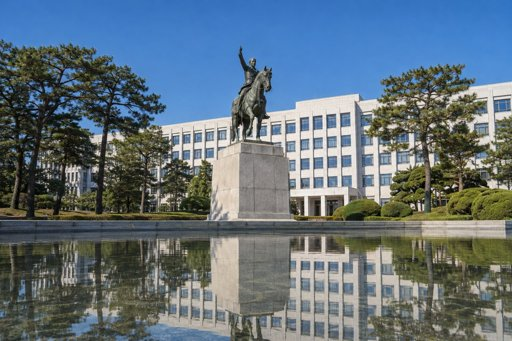

사진은 맑고 푸른 하늘 아래, 커다란 건물 앞에 세워진 기마상과 그 주변의 정원을 담고 있습니다. 화면 아래쪽에는 넓고 잔잔한 연못이 펼쳐져 있어, 동상과 건물, 나무들이 물 위에 거꾸로 비칩니다.

화면 중앙에는 밝은 회색의 높은 사각 받침대 위로 짙은 청동빛 기마상이 서 있습니다. 말 위의 인물은 몸을 곧게 세운 채 한쪽 팔을 머리 위로 높이 들어 올리고 있습니다. 말은 고개를 약간 옆으로 돌리고 앞다리 하나를 들어, 앞으로 나아가는 듯한 자세를 취하고 있습니다. 인물의 옷 주름과 말의 근육, 고삐 등이 입체적으로 표현되어 있으며, 아래에서 올려다보는 구도 덕분에 동상이 한층 웅장하게 느껴집니다.

동상 뒤로는 흰색에 가까운 밝은 회색 석재 외벽의 건물이 길게 뻗어 있습니다. 직사각형 창문들이 여러 층에 걸쳐 일정한 간격으로 줄지어 있고, 창유리에는 하늘빛이 비쳐 푸른색을 띱니다. 중앙 오른쪽 아래에는 기둥으로 둘러싸인 출입구가 보입니다. 건물의 반듯하고 규칙적인 형태가 앞쪽의 나무들과 대비됩니다.

양옆 정원에는 키 큰 소나무들이 자리하고 있습니다. 왼쪽의 소나무들은 굵은 줄기와 넓게 퍼진 가지로 화면 가장자리를 채우며, 오른쪽에도 가지가 층층이 뻗은 소나무들이 서 있습니다. 그 아래에는 둥글고 낮게 다듬어진 관목들이 짙은 초록색 덩어리를 이루고 있어, 정원이 정갈하게 관리되고 있다는 인상을 줍니다.

사진 하단을 차지하는 연못은 낮은 석재 테두리로 둘러싸여 있습니다. 수면에는 동상의 받침대와 건물의 창문, 소나무의 줄기와 가지가 비교적 선명하게 반사됩니다. 작은 물결 때문에 반영의 윤곽이 조금씩 흔들리지만, 전체적으로는 거울처럼 고요합니다.

구름이 거의 없는 짙푸른 하늘과 밝은 건물, 짙은 녹음이 뚜렷한 색 대비를 이룹니다. 선명한 햇빛 아래 동상과 나무의 그림자가 드리워져 있으며, 사람이나 차량은 보이지 않아 차분하고 엄숙한 분위기가 느껴집니다.


In [15]:
def encode_image(file_path):
    with open(file_path, "rb") as f:
        base64_image = base64.b64encode(f.read()).decode("utf-8")
    return base64_image

campus_image = encode_image("data/image/campus.jpg")
show_image("data/image/campus.jpg")

vision_response = client.responses.create(
    model="gpt-6.1-sol",
    input=[
        {
            "role": "user",
            "content": [
                {"type": "input_text", "text": "이 사진 속 장면을 한국어로 자세히 묘사해줘."},
                {
                    "type": "input_image",
                    "image_url": f"data:image/jpeg;base64,{campus_image}",
                    "detail": "high",
                },
            ],
        }
    ],
)

print(vision_response.output_text)

### 참고 자료
- https://platform.openai.com/docs/guides/image-generation
- https://platform.openai.com/docs/guides/images-vision
- https://platform.openai.com/docs/api-reference